In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('uk_used_cars_autotrader.csv')

In [4]:
from sklearn.model_selection import train_test_split

df, test = train_test_split(df, test_size=0.2, random_state=42)
df = df.reset_index(drop=True)
test = test.reset_index(drop=True)
test.to_csv('test.csv', index=False)

In [5]:
df.head()

,id,url,make,model,version,title,price_gbp,price_eur,price_evaluation,mileage_miles,...,condition,seller_type,seller_name,seller_city,seller_county,seller_zip,images_count,is_enriched,first_seen_at,last_checked_at
0,202609216231414,https://www.autotrader.co.uk/car-details/20260...,Volkswagen,Polo,1.0 EVO Life Euro 6 (s/s) 5dr,Volkswagen Polo 1.0 EVO Life Hatchback 5dr Pet...,13590,15900,NaN,27685,...,Used,Trade,Group 1 Volkswagen New Southgate,New Southgate,Middlesex,N11 3UT,20,1,2026-10-17 05:28:45.000000,2026-10-17 19:54:25.000000
1,202408233223714,https://www.autotrader.co.uk/car-details/20240...,BMW,X5,3.0d Sport Auto 4WD Euro 4 5dr,BMW X5 3.0d Sport Auto 4WD Euro 4 5dr,995,1164,NaN,119000,...,Used,Trade,MAKs Motors,Northolt,Middlesex,NaN,16,1,2026-10-17 05:15:01.000000,2026-10-17 19:15:47.000000
2,202610157032433,https://www.autotrader.co.uk/car-details/20261...,Audi,S3,2.0 TFSI Sportback S Tronic quattro Euro 6 (s/...,Audi S3 2.0 TFSI Sportback S Tronic quattro Eu...,16490,19293,NaN,70000,...,Used,Trade,Dawn Motors,Canterbury,Kent,CT2 7PX,20,1,2026-10-17 05:24:16.000000,2026-10-17 19:56:10.000000
3,202607284566536,https://www.autotrader.co.uk/car-details/20260...,Volvo,XC40,2.0 B3 MHEV Plus Black Edition DCT Auto Euro 6...,"Volvo XC40 Black Edition Plus, B3 Mild hybrid,...",31250,36562,NaN,4767,...,Used,Trade,Bells Motor Group,Northampton,Northamptonshire,NN1 5NT,17,1,2026-10-17 05:36:51.000000,2026-10-17 20:11:36.000000
4,202610066733762,https://www.autotrader.co.uk/car-details/20261...,Nissan,X-Trail,2.0 dCi Tekna Auto 4WD Euro 5 5dr (AVM),Nissan X-Trail 2.0 dCi Tekna SUV 5dr Diesel Au...,5500,6435,NaN,107000,...,Used,Trade,NaN,EXMOUTH,DEVON,NaN,20,1,2026-10-17 05:28:20.000000,2026-10-17 20:09:21.000000


In [6]:
df.describe()

,id,price_gbp,price_eur,price_evaluation,mileage_miles,mileage_km,reg_year,power_hp,power_kw,doors,seats,previous_owners,co2_gkm,annual_tax_gbp,images_count,is_enriched
count,3.839800e+05,3.839800e+05,3.839800e+05,0.0,3.839800e+05,3.839800e+05,373561.000000,383980.000000,383980.000000,375878.000000,376615.000000,322881.000000,373782.000000,366301.000000,383980.000000,383980.000000
mean,2.026051e+14,2.016287e+04,2.359051e+04,NaN,4.756377e+04,7.654628e+04,2019.368296,177.318636,132.176798,4.642908,4.974815,2.176260,129.592886,199.366709,18.302206,0.989122
std,2.436197e+10,3.911669e+04,4.576654e+04,NaN,3.838398e+04,6.177287e+04,5.359003,107.834111,80.423814,0.832719,0.766710,1.589081,59.260343,91.693920,4.884831,0.103730
min,2.014091e+14,7.500000e+01,8.800000e+01,NaN,0.000000e+00,0.000000e+00,1936.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,20.000000,0.000000,0.000000
25%,2.026081e+14,8.000000e+03,9.360000e+03,NaN,1.556700e+04,2.505300e+04,2016.000000,113.000000,84.000000,5.000000,5.000000,1.000000,111.000000,200.000000,20.000000,1.000000
50%,2.026092e+14,1.499500e+04,1.754400e+04,NaN,4.096250e+04,6.592250e+04,2020.000000,148.000000,110.000000,5.000000,5.000000,2.000000,130.000000,200.000000,20.000000,1.000000
75%,2.026100e+14,2.399500e+04,2.807400e+04,NaN,7.288325e+04,1.172942e+05,2023.000000,201.000000,150.000000,5.000000,5.000000,3.000000,154.000000,200.000000,20.000000,1.000000
max,2.026102e+14,9.999999e+06,1.170000e+07,NaN,1.480000e+06,2.381823e+06,2026.000000,1996.000000,1488.000000,7.000000,18.000000,99.000000,1300.000000,790.000000,141.000000,1.000000


In [7]:
cols_to_drop = [
    "id",                # Listing identifier
    "url",               # Advertisement link
    "price_eur",         # Reveals the target price: data leakage
    "price_evaluation",  # Entirely missing in your saved summary
    "mileage_km",        # Duplicates mileage_miles
    "power_kw",          # Duplicates power_hp
    "title",             # Initially use version for variant information
    "plate",             # Mostly overlaps with reg_year
    "seller_name",       # Can encourage memorising particular sellers
    "seller_zip",        # Initially use city/county for location
    "images_count",      # Listing detail with limited valuation value
    "is_enriched",       # Data collection flag
    "first_seen_at",     # Keep separately for history and evaluation
    "last_checked_at",   # Keep separately for listing freshness
]

In [8]:
listings = df.copy()

X = df.drop(columns=cols_to_drop + ["price_gbp"], errors="ignore")
y = df["price_gbp"]

In [9]:
# Remove selected columns, keeping price_gbp as the target
df_cleaned = df.drop(columns=cols_to_drop, errors="ignore")

# Remove columns containing only one distinct value
constant_cols = [
    col for col in df_cleaned.columns
    if col != "price_gbp" and df_cleaned[col].nunique(dropna=False) <= 1
]
df_cleaned = df_cleaned.drop(columns=constant_cols)

# Save in your notebook's working folder
df_cleaned.to_csv("used_cars_cols_dropped_01.csv", index=False)

print("Saved: used_cars_cleaned.csv")
print("Dataset shape:", df_cleaned.shape)
df_cleaned.head()

Saved: used_cars_cleaned.csv
Dataset shape: (383980, 22)


,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,...,seats,previous_owners,drivetrain,emission_class,co2_gkm,annual_tax_gbp,condition,seller_type,seller_city,seller_county
0,Volkswagen,Polo,1.0 EVO Life Euro 6 (s/s) 5dr,13590,27685,2022.0,Petrol,Manual,79,Hatchback,...,5.0,2.0,Front Wheel Drive,Euro 6,123.0,200.0,Used,Trade,New Southgate,Middlesex
1,BMW,X5,3.0d Sport Auto 4WD Euro 4 5dr,995,119000,2003.0,Diesel,Automatic,181,SUV,...,5.0,NaN,Four Wheel Drive,Euro 4,259.0,445.0,Used,Trade,Northolt,Middlesex
2,Audi,S3,2.0 TFSI Sportback S Tronic quattro Euro 6 (s/...,16490,70000,2016.0,Petrol,Automatic,306,Hatchback,...,5.0,4.0,Four Wheel Drive,Euro 6,149.0,225.0,Used,Trade,Canterbury,Kent
3,Volvo,XC40,2.0 B3 MHEV Plus Black Edition DCT Auto Euro 6...,31250,4767,2026.0,Petrol Hybrid,Automatic,161,SUV,...,5.0,NaN,Front Wheel Drive,Euro 6,152.0,200.0,Used,Trade,Northampton,Northamptonshire
4,Nissan,X-Trail,2.0 dCi Tekna Auto 4WD Euro 5 5dr (AVM),5500,107000,2014.0,Diesel,Automatic,148,SUV,...,5.0,4.0,Four Wheel Drive,Euro 5,188.0,410.0,Used,Trade,EXMOUTH,DEVON


,Missing Count,Missing (%)
previous_owners,61099,15.91
emission_class,37499,9.77
annual_tax_gbp,17679,4.60
seller_county,13299,3.46
reg_year,10419,2.71
body_color,10340,2.69
co2_gkm,10198,2.66
drivetrain,10086,2.63
doors,8102,2.11
seats,7365,1.92


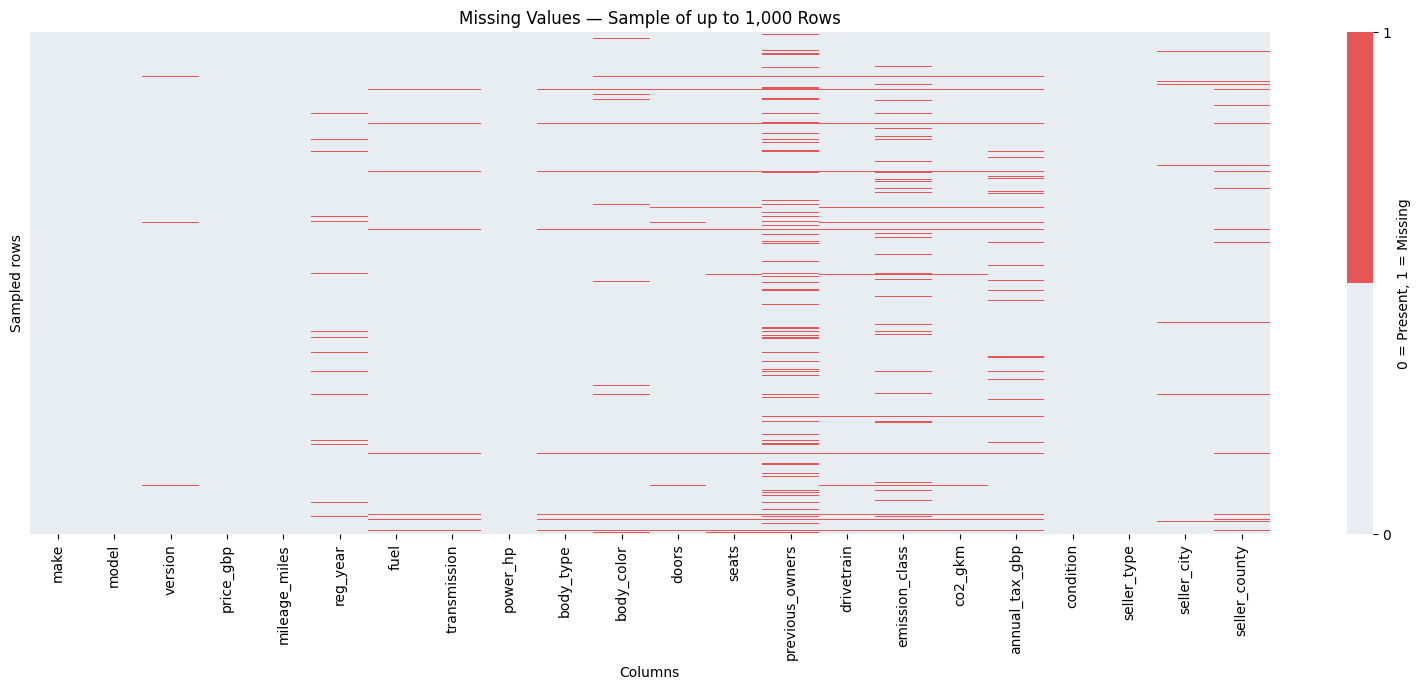

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Missing-value count and percentage for every column
missing_summary = df_cleaned.isna().sum().to_frame("Missing Count")
missing_summary["Missing (%)"] = (
    df_cleaned.isna().mean() * 100
).round(2)

display(missing_summary.sort_values("Missing Count", ascending=False))

# Sample rows to keep the heatmap readable for a large dataset
sample_df = df_cleaned.sample(
    n=min(1000, len(df_cleaned)),
    random_state=42
)

plt.figure(figsize=(16, 7))
sns.heatmap(
    sample_df.isna(),
    cmap=["#e8edf2", "#e45756"],
    vmin=0,
    vmax=1,
    yticklabels=False,
    cbar_kws={"ticks": [0, 1], "label": "0 = Present, 1 = Missing"}
)

plt.title("Missing Values — Sample of up to 1,000 Rows")
plt.xlabel("Columns")
plt.ylabel("Sampled rows")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [11]:
# Count missing values in each row
missing_per_row = df_cleaned.isna().sum(axis=1)

# Select rows with more than 5 missing values
rows_missing_gt5 = df_cleaned.loc[missing_per_row > 5]

print("Rows with more than 5 missing values:", len(rows_missing_gt5))

# Show these rows with their missing-value count
display(
    rows_missing_gt5.assign(
        missing_count=missing_per_row.loc[rows_missing_gt5.index]
    )
)

Rows with more than 5 missing values: 5761


,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,...,previous_owners,drivetrain,emission_class,co2_gkm,annual_tax_gbp,condition,seller_type,seller_city,seller_county,missing_count
10,Audi,Q3,1.5 TFSI S line Sportback S Tronic Euro 6 (s/s...,36700,5055,2026.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Trade,Exeter,NaN,12
234,Volkswagen,Tiguan,2.0 TDI Life Euro 6 (s/s) 5dr,16899,34863,2021.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Trade,Northampton,NaN,12
419,Chery,Tiggo 8,1.5T 18.4kWh Summit DHT1 Euro 6 (s/s) 5dr,32998,0,2026.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Trade,Glasgow,NaN,12
666,Volkswagen,Polo,1.2 S 5dr,1795,97506,2006.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Private,Dorking,NaN,12
773,Land Rover,Range Rover Evoque,1.5 P300e 12.2kWh Autobiography Auto 4WD Euro ...,23152,50618,2022.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Trade,Available from Towcester,NaN,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
383515,Volvo,XC60,NaN,28500,29845,2021.0,Petrol Hybrid,Automatic,0,SUV,...,2.0,NaN,NaN,NaN,200.0,Used,Private,WOOD GREEN,HARINGEY,6
383661,Ford,C-Max,1.6 16v Zetec 5dr,600,133084,2009.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Private,Paddington,NaN,12
383742,Toyota,Yaris,1.5 VVT-h Excel E-CVT Euro 6 5dr (15in Alloy),6995,109800,2015.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Trade,Solihull,NaN,12
383762,Ford,Ka,1.2 Edge Euro 5 (s/s) 3dr,1288,99632,2012.0,NaN,NaN,0,NaN,...,NaN,NaN,NaN,NaN,NaN,Used,Trade,Lytham St. Annes,NaN,12


In [12]:
# Keep rows with at most 5 missing values
rows_before = len(df_cleaned)

df_cleaned = df_cleaned.loc[
    df_cleaned.isna().sum(axis=1) <= 5
].copy()

print("Rows dropped:", rows_before - len(df_cleaned))
print("Rows remaining:", len(df_cleaned))

Rows dropped: 5761
Rows remaining: 378219


In [13]:
# Show each condition category and its row count, including missing values
print(df_cleaned["condition"].value_counts(dropna=False))

condition
Used    365907
New      12312
Name: count, dtype: int64


In [14]:
# Remove rows where condition is New
df_cleaned = df_cleaned.loc[df_cleaned["condition"] != "New"].copy()

print(df_cleaned["condition"].value_counts(dropna=False))
print("Remaining rows:", len(df_cleaned))

condition
Used    365907
Name: count, dtype: int64
Remaining rows: 365907


In [15]:
df_cleaned.to_csv("used_cars_cleaned_02.csv", index=False)

print("Saved: used_cars_cleaned_02.csv")
print("Dataset shape:", df_cleaned.shape)

Saved: used_cars_cleaned_02.csv
Dataset shape: (365907, 22)


In [16]:
df = pd.read_csv('used_cars_cleaned_02.csv')

In [17]:
df.describe()

,price_gbp,mileage_miles,reg_year,power_hp,doors,seats,previous_owners,co2_gkm,annual_tax_gbp
count,3.659070e+05,3.659070e+05,365854.000000,365907.000000,363259.000000,363801.000000,321598.000000,361412.000000,354613.000000
mean,1.927213e+04,4.901073e+04,2019.380354,177.753432,4.640975,4.969263,2.175912,131.128482,199.307837
std,3.665511e+04,3.792034e+04,5.256686,104.567011,0.832958,0.760183,1.583804,57.651165,93.160399
min,7.500000e+01,0.000000e+00,1936.000000,0.000000,0.000000,1.000000,0.000000,0.000000,20.000000
25%,7.995000e+03,1.768000e+04,2016.000000,114.000000,5.000000,5.000000,1.000000,112.000000,200.000000
50%,1.458900e+04,4.247900e+04,2020.000000,148.000000,5.000000,5.000000,2.000000,130.000000,200.000000
75%,2.299000e+04,7.395750e+04,2023.000000,201.000000,5.000000,5.000000,3.000000,154.000000,200.000000
max,9.999999e+06,1.480000e+06,2026.000000,1898.000000,7.000000,18.000000,99.000000,1300.000000,790.000000


In [18]:
# Missing-value count and percentage for each column
missing_summary = df.isna().sum().to_frame("Missing Count")
missing_summary["Missing (%)"] = (df.isna().mean() * 100).round(2)

display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing (%)
previous_owners,44309,12.11
emission_class,27565,7.53
annual_tax_gbp,11294,3.09
seller_county,7935,2.17
body_color,5298,1.45
co2_gkm,4495,1.23
drivetrain,4481,1.22
seller_city,3183,0.87
doors,2648,0.72
seats,2106,0.58


In [19]:
# Fill missing categorical values with "Unknown"
unknown_cols = [
    "emission_class",
    "seller_county",
    "body_color",
    "drivetrain",
    "seller_city",
    "version"
]

df[unknown_cols] = df[unknown_cols].fillna("Unknown")

# Check remaining missing values in these columns
print(df[unknown_cols].isna().sum())

emission_class    0
seller_county     0
body_color        0
drivetrain        0
seller_city       0
version           0
dtype: int64


In [20]:
# Drop rows with missing registration year
df = df.dropna(subset=["reg_year"]).copy()

print("Remaining rows:", len(df))
print("Missing reg_year:", df["reg_year"].isna().sum())

Remaining rows: 365854
Missing reg_year: 0


In [21]:
for col in ["doors", "seats"]:
    group_mode = df.groupby(
        ["make", "model", "body_type"]
    )[col].transform(
        lambda s: s.mode().iloc[0] if not s.mode().empty else float("nan")
    )

    df[col] = (
        df[col]
        .fillna(group_mode)
        .fillna(df[col].mode().iloc[0])
        .astype(int)
    )

print(df[["doors", "seats"]].isna().sum())

doors    0
seats    0
dtype: int64


In [22]:
df.to_csv("used_cars_cleaned_03.csv", index=False)

print("Saved: used_cars_cleaned_03.csv")
print("Dataset shape:", df.shape)

Saved: used_cars_cleaned_03.csv
Dataset shape: (365854, 22)


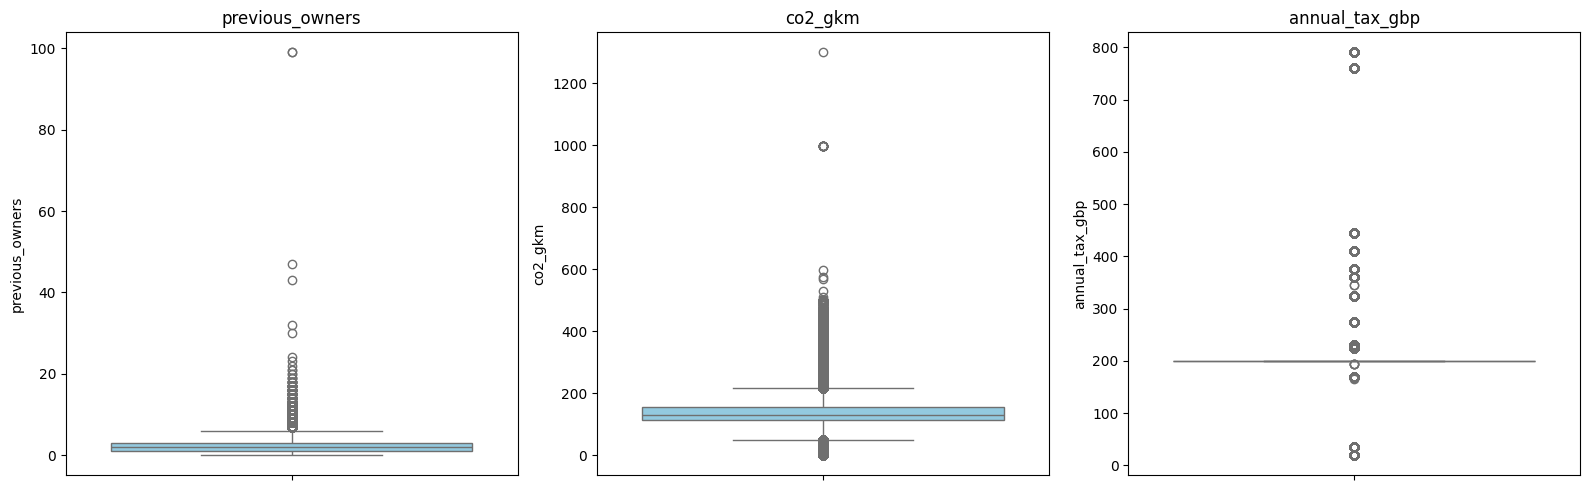

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = ["previous_owners", "co2_gkm", "annual_tax_gbp"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, columns):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [24]:
columns = ["previous_owners", "co2_gkm", "annual_tax_gbp"]
results = []

for col in columns:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (values < lower) | (values > upper)

    results.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": outliers.sum(),
        "Outlier (%)": round(outliers.mean() * 100, 2)
    })

display(pd.DataFrame(results))

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
0,previous_owners,-2.0,6.0,5846,1.82
1,co2_gkm,49.0,217.0,59987,16.60
2,annual_tax_gbp,200.0,200.0,86464,24.38


In [25]:
columns = ["previous_owners", "co2_gkm", "annual_tax_gbp"]
results = []

for col in columns:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    upper_bound = q3 + 1.5 * (q3 - q1)

    upper_outliers = values[values > upper_bound]

    results.append({
        "Column": col,
        "Upper Bound": upper_bound,
        "Smallest Upper Outlier": upper_outliers.min(),
        "Maximum Value": values.max(),
        "Upper Outlier Count": len(upper_outliers)
    })

display(pd.DataFrame(results))

,Column,Upper Bound,Smallest Upper Outlier,Maximum Value,Upper Outlier Count
0,previous_owners,6.0,7.0,99.0,5846
1,co2_gkm,217.0,218.0,1300.0,23128
2,annual_tax_gbp,200.0,225.0,790.0,38402


In [26]:
count = (df["previous_owners"] >= 8).sum()
print("Rows with previous_owners >= 8:", count)

Rows with previous_owners >= 8: 3060


In [27]:
rows_before = len(df)

# Remove rows with 8 or more previous owners; keep missing values
df = df.loc[
    df["previous_owners"].isna() |
    (df["previous_owners"] < 8)
].copy()

print("Rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))

Rows removed: 3060
Rows remaining: 362794


In [28]:
# Convert grams per kilometre to grams per mile
df["co2_gmile"] = df["co2_gkm"] * 1.609344

# Remove the original column
df = df.drop(columns=["co2_gkm"])

print(df["co2_gmile"].head())

0    197.949312
1    416.820096
2    239.792256
3    244.620288
4    302.556672
Name: co2_gmile, dtype: float64


In [29]:
df.to_csv("used_cars_cleaned_04.csv", index=False)

print("Saved: used_cars_cleaned_04.csv")
print("Dataset shape:", df.shape)

Saved: used_cars_cleaned_04.csv
Dataset shape: (362794, 22)


In [30]:
# Round to the nearest integer while preserving missing values
df["co2_gmile"] = df["co2_gmile"].round().astype("Int64")

print(df["co2_gmile"].head())

0    198
1    417
2    240
3    245
4    303
Name: co2_gmile, dtype: Int64


In [31]:
import pandas as pd

columns = ["previous_owners", "co2_gmile", "annual_tax_gbp"]
results = []

for col in columns:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    low_outliers = values[values < lower]
    high_outliers = values[values > upper]

    results.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Smallest Upper Outlier": high_outliers.min(),
        "Largest Upper Outlier": high_outliers.max(),
        "Upper Outlier Count": len(high_outliers),
        "Smallest Lower Outlier": low_outliers.min(),
        "Largest Lower Outlier": low_outliers.max(),
        "Lower Outlier Count": len(low_outliers)
    })

display(pd.DataFrame(results).round(2))

,Column,Lower Bound,Upper Bound,Smallest Upper Outlier,Largest Upper Outlier,Upper Outlier Count,Smallest Lower Outlier,Largest Lower Outlier,Lower Outlier Count
0,previous_owners,-2.0,6.0,7.0,7.0,2786,NaN,NaN,0
1,co2_gmile,78.0,350.0,351.0,2092.0,22325,0.0,77.0,36854
2,annual_tax_gbp,200.0,200.0,225.0,790.0,36390,20.0,195.0,47497


In [32]:
# Overwrite the previous CSV with the updated data
df.to_csv("used_cars_cleaned_04.csv", index=False)

print("Updated: used_cars_cleaned_04.csv")

Updated: used_cars_cleaned_04.csv


In [33]:
import pandas as pd

# Load the latest saved CSV
df = pd.read_csv("used_cars_cleaned_04.csv")

# Missing values in every column
missing_summary = df.isna().sum().to_frame("Missing Count")
missing_summary["Missing (%)"] = (df.isna().mean() * 100).round(2)

display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing (%)
previous_owners,44282,12.21
annual_tax_gbp,11160,3.08
co2_gmile,4209,1.16
version,0,0.00
make,0,0.00
model,0,0.00
reg_year,0,0.00
mileage_miles,0,0.00
price_gbp,0,0.00
fuel,0,0.00


In [34]:
columns = ["previous_owners", "annual_tax_gbp", "co2_gmile"]

print(df[columns].median().rename("Median"))

previous_owners      2.0
annual_tax_gbp     200.0
co2_gmile          209.0
Name: Median, dtype: float64


In [35]:
col = "annual_tax_gbp"

# Preserve or create the original missing-value indicator
if "annual_tax_gbp_missing" not in df.columns:
    df["annual_tax_gbp_missing"] = df[col].isna().astype(int)

missing_mask = (
    df["annual_tax_gbp_missing"].eq(1) | df[col].isna()
)

# Use only originally recorded tax values
known_tax = df[col].astype("float64").mask(missing_mask)
reference = df.assign(annual_tax_gbp=known_tax)
filled = known_tax.copy()

groups = [
    ["make", "model", "version", "fuel", "reg_year"],
    ["make", "model", "fuel", "reg_year"],
    ["fuel", "reg_year"]
]

for group in groups:
    group_median = reference.groupby(group)[col].transform("median")
    filled = filled.fillna(group_median)

# Overall median as the final fallback
df[col] = filled.fillna(known_tax.median())

print("Remaining missing:", df[col].isna().sum())

Remaining missing: 0


In [36]:
# Record which values were originally missing
df["co2_gmile_missing"] = df["co2_gmile"].isna().astype(int)

# Calculate replacements from known values
known = df.copy()
filled = df["co2_gmile"].astype("float64")

groups = [
    ["make", "model", "version", "fuel", "reg_year"],
    ["make", "model", "fuel", "reg_year"],
    ["make", "model", "fuel"],
    ["fuel", "body_type"]
]

for group in groups:
    group_median = known.groupby(group)["co2_gmile"].transform("median")
    filled = filled.fillna(group_median)

# Overall median only if no matching group has known values
df["co2_gmile"] = (
    filled.fillna(known["co2_gmile"].median())
    .round()
    .astype("Int64")
)

print("Remaining missing:", df["co2_gmile"].isna().sum())

Remaining missing: 0


In [37]:
col = "previous_owners"

# Preserve or create the original missing-value indicator
if "previous_owners_missing" not in df.columns:
    df["previous_owners_missing"] = df[col].isna().astype(int)

missing_mask = (
    df["previous_owners_missing"].eq(1) | df[col].isna()
)

# Exclude any previously imputed values when calculating medians
known_owners = df[col].astype("float64").mask(missing_mask)
reference = df.assign(previous_owners=known_owners)

year_median = reference.groupby("reg_year")[col].transform("median")

estimates = (
    year_median
    .fillna(known_owners.median())
    .round()
)

df[col] = known_owners.fillna(estimates).astype("Int64")

print("Remaining missing:", df[col].isna().sum())

Remaining missing: 0


In [38]:
df.to_csv("used_cars_cleaned_05.csv", index=False)

print("Saved: used_cars_cleaned_05.csv")
print("Dataset shape:", df.shape)

Saved: used_cars_cleaned_05.csv
Dataset shape: (362794, 25)


In [39]:
import pandas as pd

df = pd.read_csv("used_cars_cleaned_05.csv")

missing_summary = df.isna().sum().to_frame("Missing Count")
missing_summary["Missing (%)"] = (df.isna().mean() * 100).round(2)

display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing (%)
make,0,0.0
model,0,0.0
version,0,0.0
price_gbp,0,0.0
mileage_miles,0,0.0
reg_year,0,0.0
fuel,0,0.0
transmission,0,0.0
power_hp,0,0.0
body_type,0,0.0


In [40]:
# Numeric measurements, excluding missing-value indicator columns
numeric_cols = [
    col for col in df.select_dtypes(include="number").columns
    if not col.endswith("_missing")
]

results = []

for col in numeric_cols:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    low_outliers = values[values < lower]
    high_outliers = values[values > upper]
    count = len(low_outliers) + len(high_outliers)

    results.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Lower Outliers": len(low_outliers),
        "Upper Outliers": len(high_outliers),
        "Total Outliers": count,
        "Outlier (%)": round(count / len(values) * 100, 2)
        if len(values) else 0
    })

outlier_summary = pd.DataFrame(results)

display(
    outlier_summary
    .sort_values("Total Outliers", ascending=False)
    .round(2)
)

,Column,Lower Bound,Upper Bound,Lower Outliers,Upper Outliers,Total Outliers,Outlier (%)
7,annual_tax_gbp,200.00,200.00,48818,37596,86414,23.82
4,doors,5.00,5.00,68208,1097,69305,19.10
5,seats,5.00,5.00,40566,21589,62155,17.13
8,co2_gmile,78.00,350.00,36984,23002,59986,16.53
3,power_hp,-16.50,331.50,0,29231,29231,8.06
0,price_gbp,-14505.00,45495.00,0,20349,20349,5.61
2,reg_year,2005.50,2033.50,4106,0,4106,1.13
1,mileage_miles,-65928.62,156550.38,0,2809,2809,0.77
6,previous_owners,-2.00,6.00,0,2786,2786,0.77


In [41]:
import pandas as pd

numeric_cols = [
    col for col in df.select_dtypes(include="number").columns
    if not col.endswith("_missing")
]

results = []

for col in numeric_cols:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    low_outliers = values[values < lower]
    high_outliers = values[values > upper]

    results.append({
        "Column": col,
        "Lowest Lower Outlier": low_outliers.min(),
        "Highest Lower Outlier": low_outliers.max(),
        "Lower Outlier Count": len(low_outliers),
        "Lowest Upper Outlier": high_outliers.min(),
        "Highest Upper Outlier": high_outliers.max(),
        "Upper Outlier Count": len(high_outliers)
    })

display(pd.DataFrame(results).round(2))

,Column,Lowest Lower Outlier,Highest Lower Outlier,Lower Outlier Count,Lowest Upper Outlier,Highest Upper Outlier,Upper Outlier Count
0,price_gbp,NaN,NaN,0,45498.0,9999999.0,20349
1,mileage_miles,NaN,NaN,0,156556.0,1480000.0,2809
2,reg_year,1936.0,2005.0,4106,NaN,NaN,0
3,power_hp,NaN,NaN,0,333.0,1898.0,29231
4,doors,0.0,4.0,68208,6.0,7.0,1097
5,seats,1.0,4.0,40566,6.0,18.0,21589
6,previous_owners,NaN,NaN,0,7.0,7.0,2786
7,annual_tax_gbp,20.0,195.0,48818,212.5,790.0,37596
8,co2_gmile,0.0,77.0,36984,351.0,2092.0,23002


In [42]:
import pandas as pd

results = []

for col in df.select_dtypes(include="number").columns:
    if col.endswith("_missing"):
        continue

    threshold = df[col].quantile(0.99)
    above = df[col] > threshold

    results.append({
        "Column": col,
        "99th Percentile": threshold,
        "Count Above": above.sum(),
        "Maximum": df[col].max()
    })

display(pd.DataFrame(results).round(2))

,Column,99th Percentile,Count Above,Maximum
0,price_gbp,94500.00,3625,9999999.0
1,mileage_miles,150081.19,3628,1480000.0
2,reg_year,2026.00,0,2026.0
3,power_hp,575.00,3604,1898.0
4,doors,5.00,1097,7.0
5,seats,7.00,1659,18.0
6,previous_owners,6.00,2786,7.0
7,annual_tax_gbp,760.00,2277,790.0
8,co2_gmile,475.00,3555,2092.0


In [43]:
high_power = df.loc[df["co2_gmile"] > 500]

print("Rows above 500 co2_gmile:", len(high_power))
print("Distinct fuels:", high_power["fuel"].unique())
print("Distinct makes:", high_power["make"].unique())
print("Number of distinct makes:", high_power["make"].nunique())

Rows above 500 co2_gmile: 2494
Distinct fuels: ['Petrol' 'Petrol Hybrid' 'Diesel' 'Unlisted' 'Bi Fuel'
 'Petrol Plug-in Hybrid']
Distinct makes: ['Porsche' 'Aston Martin' 'Ford' 'Rolls-Royce' 'Jaguar' 'Jeep' 'Audi'
 'Ferrari' 'Land Rover' 'Lamborghini' 'Mercedes-Benz' 'Bentley' 'Maserati'
 'Mitsubishi' 'BMW' 'Toyota' 'INEOS' 'GWM' 'Volkswagen' 'Dodge' 'Cadillac'
 'TVR' 'Chevrolet' 'Ram' 'Hummer' 'Vauxhall' 'Maybach' 'Nissan' 'Isuzu'
 'Lotus' 'SsangYong' 'Bugatti' 'Chrysler' 'McLaren' 'MG']
Number of distinct makes: 35


In [44]:
cols = [
    "make", "model", "version", "reg_year",
    "fuel", "power_hp", "co2_gmile"
]

display(
    df.loc[df["co2_gmile"] > 500, cols]
    .sort_values("co2_gmile", ascending=False)
    .head(30)
)

,make,model,version,reg_year,fuel,power_hp,co2_gmile
233716,Ford,Puma,1.0T EcoBoost MHEV ST-Line X DCT Euro 6 (s/s) 5dr,2026.0,Petrol Hybrid,123,2092
12123,GWM,POER300,2.4D Ultra Auto 4WD Euro 6 (s/s) 4dr,2026.0,Diesel,180,1608
304626,Land Rover,Range Rover Sport,3.0 P440e 38.2kWh Dynamic SE Auto 4WD Euro 6 (...,2022.0,Petrol Plug-in Hybrid,434,1608
115855,Ford,Focus,1.0T EcoBoost ST-Line X Euro 6 (s/s) 5dr,2023.0,Petrol,123,1608
352558,Nissan,Juke,1.6 Tekna Auto Euro 6 5dr,2023.0,Petrol Hybrid,141,1608
213974,Isuzu,D-Max,1.9 TD XTR Nav+ Auto 4WD Euro 6 4dr,2021.0,Diesel,162,1608
121353,Isuzu,D-Max,1.9 TD XTR Nav+ 4WD Euro 6 4dr,2021.0,Diesel,162,1608
132947,GWM,POER300,2.4D Ultra Auto 4WD Euro 6 (s/s) 4dr,2026.0,Diesel,180,1608
190725,SsangYong,Musso,2.2D Rebel Auto 4WD Euro 6 4dr,2021.0,Diesel,179,1608
34645,GWM,POER300,2.4D Ultra Auto 4WD Euro 6 (s/s) 4dr,2025.0,Diesel,180,1608


In [45]:
import pandas as pd

suspicious = df["co2_gmile"].isin([1608, 2092])

# Preserve an audit flag
df["co2_gmile_suspicious"] = suspicious.astype(int)

# Mark these values as missing
df.loc[suspicious, "co2_gmile"] = pd.NA

print("CO₂ values marked missing:", suspicious.sum())

CO₂ values marked missing: 13


In [46]:
df.head()

,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,...,annual_tax_gbp,condition,seller_type,seller_city,seller_county,co2_gmile,annual_tax_gbp_missing,co2_gmile_missing,previous_owners_missing,co2_gmile_suspicious
0,Volkswagen,Polo,1.0 EVO Life Euro 6 (s/s) 5dr,13590,27685,2022.0,Petrol,Manual,79,Hatchback,...,200.0,Used,Trade,New Southgate,Middlesex,198.0,0,0,0,0
1,BMW,X5,3.0d Sport Auto 4WD Euro 4 5dr,995,119000,2003.0,Diesel,Automatic,181,SUV,...,445.0,Used,Trade,Northolt,Middlesex,417.0,0,0,1,0
2,Audi,S3,2.0 TFSI Sportback S Tronic quattro Euro 6 (s/...,16490,70000,2016.0,Petrol,Automatic,306,Hatchback,...,225.0,Used,Trade,Canterbury,Kent,240.0,0,0,0,0
3,Volvo,XC40,2.0 B3 MHEV Plus Black Edition DCT Auto Euro 6...,31250,4767,2026.0,Petrol Hybrid,Automatic,161,SUV,...,200.0,Used,Trade,Northampton,Northamptonshire,245.0,0,0,1,0
4,Nissan,X-Trail,2.0 dCi Tekna Auto 4WD Euro 5 5dr (AVM),5500,107000,2014.0,Diesel,Automatic,148,SUV,...,410.0,Used,Trade,EXMOUTH,DEVON,303.0,0,0,0,0


In [47]:
import pandas as pd

col = "co2_gmile"

# Remove the flag column if it exists
df = df.drop(columns=["co2_gmile_suspicious"], errors="ignore")

# Exclude suspicious values from the reference data
known = pd.to_numeric(df[col], errors="coerce")
known = known.mask(known.isin([1608, 2092]))

reference = df.assign(co2_gmile=known)
filled = known.copy()
missing_before = filled.isna().sum()

groups = [
    ["make", "model", "version", "fuel", "transmission", "reg_year"],
    ["make", "model", "version", "fuel", "transmission"],
    ["make", "model", "fuel", "transmission", "reg_year"],
    ["make", "model", "fuel", "transmission"],
    ["make", "model", "fuel"],
    ["fuel", "body_type"],
    ["fuel"]
]

for group in groups:
    group_median = reference.groupby(
        group, dropna=False, observed=True
    )[col].transform("median")

    filled = filled.fillna(group_median)

# Final fallback
filled = filled.fillna(known.median())

# Preserve recorded values; round replacements
df[col] = known.fillna(filled.round()).astype("Int64")

print("Values filled:", missing_before - df[col].isna().sum())
print("Remaining missing:", df[col].isna().sum())

Values filled: 13
Remaining missing: 0


In [49]:
df.to_csv("used_cars_cleaned_06.csv", index=False)

print("Saved: used_cars_cleaned_06.csv")
print("Dataset shape:", df.shape)

Saved: used_cars_cleaned_06.csv
Dataset shape: (362794, 25)


In [50]:
import pandas as pd

df = pd.read_csv("used_cars_cleaned_06.csv")

# Count values below 2
print("Rows with doors < 2:", (df["doors"] < 2).sum())
print("Rows with seats < 2:", (df["seats"] < 2).sum())

# Show rows meeting either condition
display(df.loc[(df["doors"] < 2) | (df["seats"] < 2)])

Rows with doors < 2: 121
Rows with seats < 2: 12


,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,...,emission_class,annual_tax_gbp,condition,seller_type,seller_city,seller_county,co2_gmile,annual_tax_gbp_missing,co2_gmile_missing,previous_owners_missing
9185,Ford,Tourneo Custom,2.5 340 Duratec 11.8kWh Titanium Auto L2 Euro ...,51000,3072,2026.0,Petrol Plug-in Hybrid,Automatic,229,Minibus,...,Euro 6,200.0,Used,Trade,Derby,Derbyshire,71,1,0,0
10647,Vauxhall,Combo,1.5 Turbo D 2300 Prime XL Crew Van LWB Euro 6 ...,20498,7931,2026.0,Diesel,Manual,101,Combi Van,...,Euro 6,200.0,Used,Trade,Wellingborough,Northamptonshire,243,1,0,1
14227,Land Rover,Defender 110,2.5 TDi County Station Wagon MWB,9995,149850,1997.0,Diesel,Manual,111,SUV,...,Unknown,375.0,Used,Trade,Wakefield,West Yorkshire,372,1,1,1
18317,Land Rover,Defender 90,2.5 TDi Station Wagon SWB,20995,83000,1998.0,Diesel,Manual,111,SUV,...,Unknown,375.0,Used,Trade,Cranleigh,Surrey,365,1,1,1
18455,Suzuki,Jimny,Sierra Hatchback 1.5 Automatic Petrol,22990,11630,2024.0,Petrol,Automatic,0,SUV,...,Unknown,200.0,Used,Trade,Croydon,Surrey,278,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
353178,Audi,A3,1.4 1.4 Hatchback Petrol,17995,25197,2020.0,Petrol,Unlisted,0,Hatchback,...,Unknown,200.0,Used,Trade,Romsey,Hampshire,216,0,1,0
358782,Land Rover,Series III,2.3D 109,9500,109222,1968.0,Diesel,Manual,60,SUV,...,Unknown,200.0,Used,Private,DEWSBURY,WEST YORKSHIRE,248,1,1,0
360160,Toyota,Hilux,2.8 D-4D-h Invincible X Auto 4WD Euro 6 4dr,42990,6000,2025.0,Diesel Hybrid,Automatic,201,Pickup,...,Euro 6,200.0,Used,Trade,Stafford,Staffordshire,426,1,0,0
361766,Ford,Transit Custom,2.0 320 EcoBlue Limited Crew Van L2 H1 Euro 6 ...,32159,31418,2025.0,Diesel,Manual,148,Combi Van,...,Euro 6,200.0,Used,Trade,Sudbury,Suffolk,315,1,0,0


In [51]:
import numpy as np

for col in ["doors", "seats"]:
    # Treat values below 2 as missing
    df.loc[df[col] < 2, col] = np.nan

    # Use known values from similar vehicles
    reference = df.copy()
    filled = df[col].copy()

    groups = [
        ["make", "model", "version", "body_type"],
        ["make", "model", "body_type"],
        ["body_type"]
    ]

    def most_common(series):
        modes = series.mode()
        return modes.iloc[0] if not modes.empty else np.nan

    for group in groups:
        group_mode = reference.groupby(
            group, dropna=False, observed=True
        )[col].transform(most_common)

        filled = filled.fillna(group_mode)

    # Overall mode as the final fallback
    df[col] = filled.fillna(most_common(reference[col])).astype("Int64")

print("Remaining missing values:")
print(df[["doors", "seats"]].isna().sum())

Remaining missing values:
doors    0
seats    0
dtype: int64


In [52]:
df.to_csv("used_cars_cleaned_07.csv", index=False)

print("Saved:", df.shape)

Saved: (362794, 25)


In [53]:
# Missing values in every column of the current dataset
missing_summary = df.isna().sum().to_frame("Missing Count")
missing_summary["Missing (%)"] = (df.isna().mean() * 100).round(2)

display(missing_summary.sort_values("Missing Count", ascending=False))

print("Total missing values:", df.isna().sum().sum())

,Missing Count,Missing (%)
make,0,0.0
model,0,0.0
version,0,0.0
price_gbp,0,0.0
mileage_miles,0,0.0
reg_year,0,0.0
fuel,0,0.0
transmission,0,0.0
power_hp,0,0.0
body_type,0,0.0


Total missing values: 0
